<a href="https://colab.research.google.com/github/Sakshit16/practical9/blob/main/EE518_task10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

In [ ]:
class Layer:
  def __init__(self):
    self.input = None
    self.output = None
  def forward(self, input):
    pass
  def backward(self, output_gradient, learning_rate):
    pass

In [ ]:
class Dense(Layer):
  def __init__(self, input_size, output_size):
    self.weights = np.random.randn(output_size, input_size)
    self.bias = np.random.randn(output_size, 1)

  def forward(self, input):
    self.input = input
    return np.dot(self.weights, self.input) + self.bias

  def backward(self, output_gradient, learning_rate):
    weights_gradient = np.dot(output_gradient, self.input.T)
    input_gradient = np.dot(self.weights.T, output_gradient)
    self.weights -= learning_rate * weights_gradient
    self.bias -= learning_rate * output_gradient
    return input_gradient

In [ ]:
def mse(y_true, y_pred):
  return np.mean(np.power(y_true-y_pred, 2));
def mse_prime(y_true, y_pred):
  return 2*(y_pred-y_true)/np.size(y_true);

In [ ]:
class Activation(Layer):
  def __init__(self, activation, activation_prime):
    self.activation = activation
    self.activation_prime = activation_prime
  def forward(self, input):
    self.input = input
    return self.activation(self.input)
  def backward(self, output_gradient, learning_rate):
    return np.multiply(output_gradient, self.activation_prime(self.input))

In [ ]:
class Tanh(Activation):
  def __init__(self):
    def tanh(x):
      return np.tanh(x)
    def tanh_prime(x):
      return 1 - np.tanh(x)**2
    super().__init__(tanh, tanh_prime)

class Sigmoid(Activation):
  def __init__(self):
    def sigmoid(x):
      return 1 / (1 + np.exp(-x))
    def sigmoid_prime(x):
      s = sigmoid(x)
      return s * (1 - s)
    super().__init__(sigmoid, sigmoid_prime)

In [ ]:
import math

In [ ]:
class Linear(Activation):
  def __init__(self):
    def linear(x):
      return x
    def linear_prime(x):
      return 1
    super().__init__(linear, linear_prime)

In [ ]:
import numpy as np
x_train=np.linspace(-3,3,61)
y_train=[math.sin(p)for p in x_train]

network=[Dense(1,10),Tanh(),Dense(10,1),Linear()]

epochs=50
learning_rate=0.01
errorlist=[]

for e in range(epochs):
  error=0
  for x,y in zip(x_train,y_train):

    output=np.array([[x]])
    target=np.array([[y]])

    for layer in network:
      output=layer.forward(output)
    error+=mse(target,output)

    grad=mse_prime(target,output)
    for layer in reversed(network):
      grad=layer.backward(grad,learning_rate)
  error/=len(x_train)
  print(f"{e+1}/{epochs}, error={error}")
  errorlist.append(error)

1/50, error=0.12174296727672194
2/50, error=0.19662389797463575
3/50, error=0.07682543494861799
4/50, error=0.039634260186834136
5/50, error=0.02119170645905842
6/50, error=0.016089500272159732
7/50, error=0.014086803905706671
8/50, error=0.012758256202810786
9/50, error=0.01158391698260184
10/50, error=0.01042791898909619
11/50, error=0.009376151017300813
12/50, error=0.008511718732382665
13/50, error=0.007904702746874949
14/50, error=0.007575324429438573
15/50, error=0.007495425192449693
16/50, error=0.007602216681058986
17/50, error=0.007819984749543114
18/50, error=0.008078340613991779
19/50, error=0.008322131436783089
20/50, error=0.008514310745634397
21/50, error=0.008634500611684357
22/50, error=0.00867574768647742
23/50, error=0.008640805367857812
24/50, error=0.008538648686543256
25/50, error=0.008381534073853381
26/50, error=0.008182739166573689
27/50, error=0.007954992294959589
28/50, error=0.007709521033140873
29/50, error=0.00745559900166498
30/50, error=0.0072004530832825

In [ ]:
actual_y=[]
for x in x_train:
  output=np.array([[x]])
  for layer in network:
    output=layer.forward(output)
  actual_y.append(output[0,0])
print(actual_y)

[np.float64(-0.46915250013597315), np.float64(-0.520191202354374), np.float64(-0.5707654971635515), np.float64(-0.6204647595221265), np.float64(-0.6688146384073919), np.float64(-0.7152701965386132), np.float64(-0.7592107261802756), np.float64(-0.7999381748997856), np.float64(-0.8366819841128451), np.float64(-0.8686140782983247), np.float64(-0.8948784956245666), np.float64(-0.9146402565469489), np.float64(-0.9271568012558074), np.float64(-0.931871763328368), np.float64(-0.9285241263529267), np.float64(-0.9172557204284195), np.float64(-0.8986878448405093), np.float64(-0.8739271206672234), np.float64(-0.8444573231045598), np.float64(-0.8118845145531497), np.float64(-0.7775317724992046), np.float64(-0.7419270289542004), np.float64(-0.7042884566089798), np.float64(-0.6621798520644498), np.float64(-0.6115714600257844), np.float64(-0.547559515731856), np.float64(-0.46586614776424057), np.float64(-0.36481957983335284), np.float64(-0.2468618218700928), np.float64(-0.11834149691656808), np.float

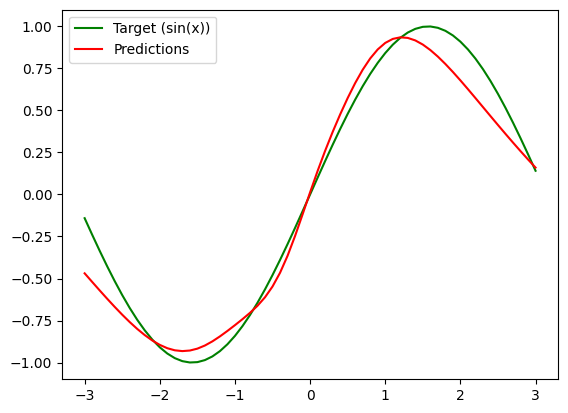

In [ ]:
import matplotlib.pyplot as plt
plt.plot(x_train, y_train, color='green', label='Target (sin(x))')
plt.plot(x_train, actual_y, color='red', label='Predictions')
plt.legend()
plt.show()